# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
from aitlas.datasets import WiDSDatathon2019Dataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

New train/val/test split

In [ ]:
dataset_config = {
    "data_dir": "./data/widsdatathon2019/",
    "csv_file": "./data/widsdatathon2019/widsdatathon2019_train.csv",
}
dataset = WiDSDatathon2019Dataset(dataset_config)
print(len(dataset))

12461


Original train/val/test split

In [ ]:
dataset_config = {
    "data_dir": "./data/widsdatathon2019/train_images",
    "csv_file": "./data/widsdatathon2019/traininglabels.csv",
}
dataset = WiDSDatathon2019Dataset(dataset_config)
print(len(dataset))

15057


## Show images from the dataset

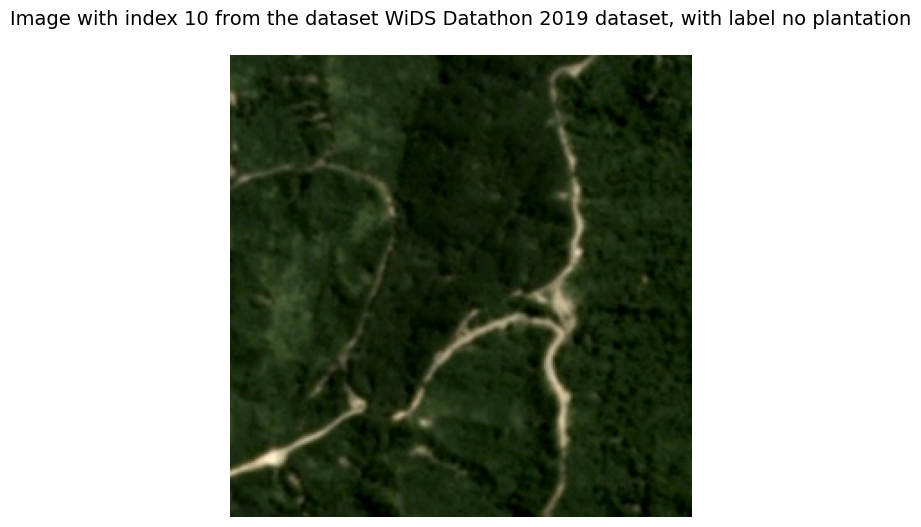

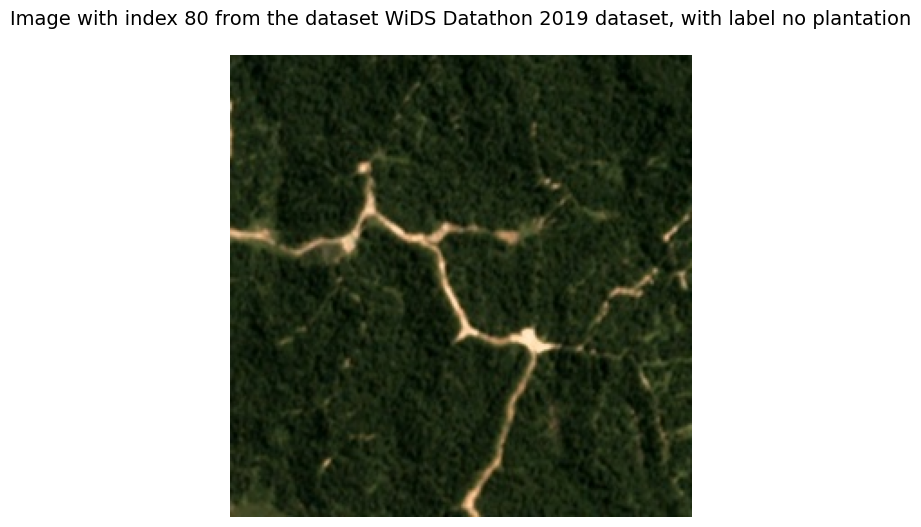

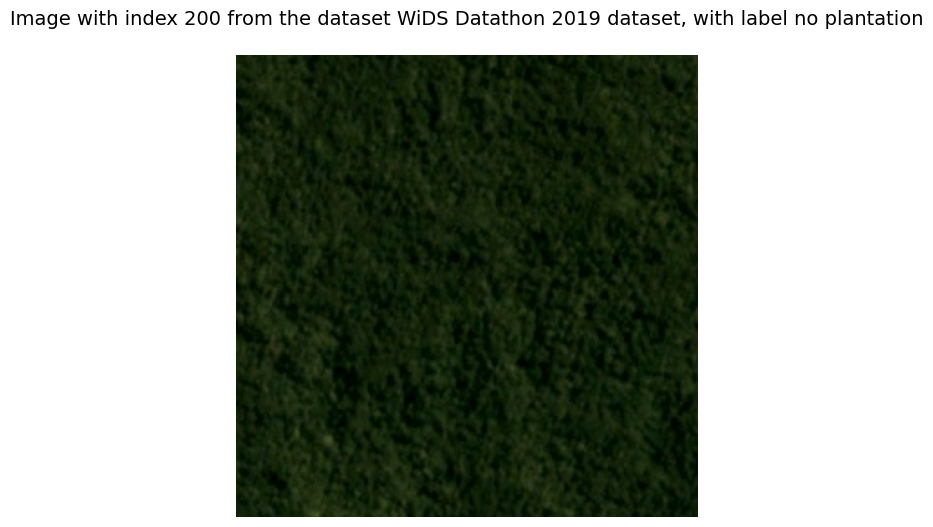

In [13]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

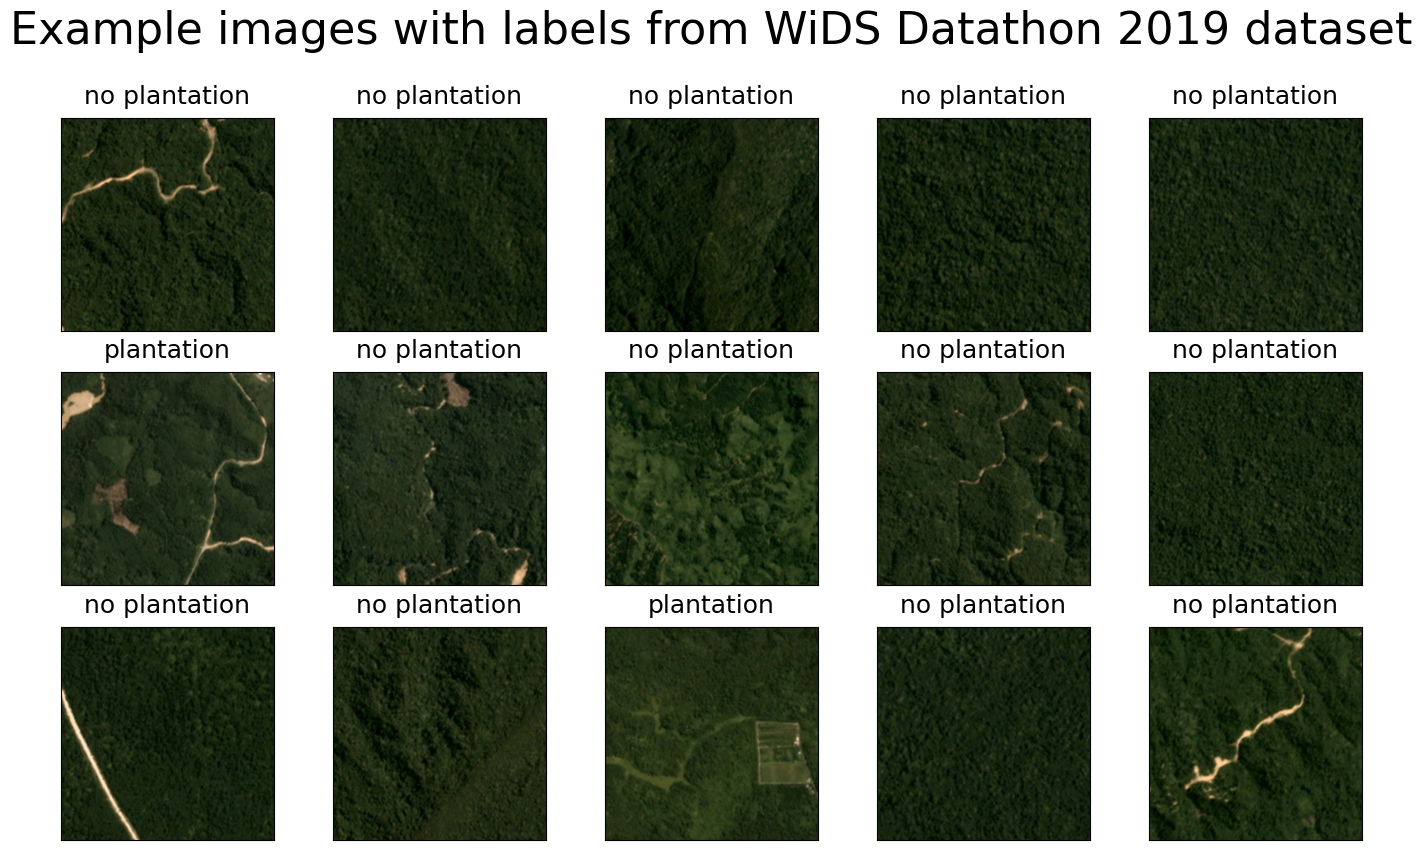

In [15]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [16]:
dataset.show_samples()

,File name,Label
image_id,has_oilpalm,score
img_000002017.jpg,0,0.7895
img_000012017.jpg,0,1
img_000022017.jpg,0,1
img_000072017.jpg,0,1
img_000082017.jpg,0,1
img_000092017.jpg,0,1
img_000102017.jpg,0,1
img_000112017.jpg,0,0.8352
img_000132017.jpg,0,1


In [17]:
dataset.data_distribution_table()

,Label,Count
0,no plantation,14302
1,plantation,942


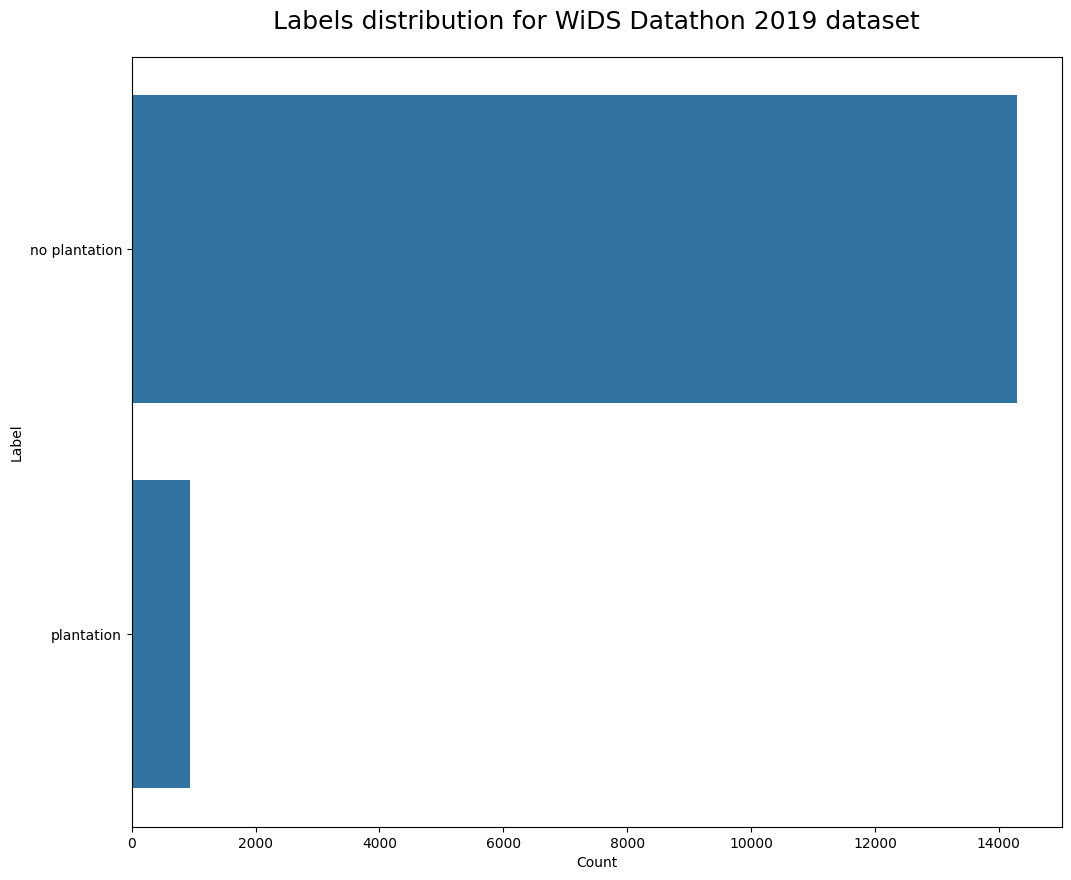

In [49]:
fig = dataset.data_distribution_barchart() 

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/widsdatathon2019/train_images/",
    "csv_file": "./data/widsdatathon2019/traininglabels.csv",
}

train_dataset = WiDSDatathon2019Dataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/widsdatathon2019/leaderboard_test_data/",
    "csv_file": "./data/widsdatathon2019/testlabels.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = WiDSDatathon2019Dataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(15057, 3534)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/widsdatathon2019/"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-20 09:53:34,783 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-20 09:53:34,961 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [26]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-20 09:16:02,901 INFO Starting training.
training: 100%|██████████| 471/471 [01:59<00:00,  3.94it/s]
2025-05-20 09:18:02,563 INFO epoch: 1, time: 120, loss:  0.20298
testing on train set: 100%|██████████| 471/471 [00:41<00:00, 11.39it/s]
2025-05-20 09:18:46,185 INFO Accuracy:0.9378362223550508, Precision Micro:0.9378362223550508, Precision Macro:0.4689181111775254, Precision Weighted:0.8795367799611923, Precision per Class:[0.93783622 0.        ], Recall Micro:0.9378362223550508, Recall Macro:0.5, Recall Weighted:0.9378362223550508, Recall per Class:[1. 0.], F1_score Micro:0.9378362223550503, F1_score Macro:0.48396051819864255, F1_score Weighted:0.9077514083128155, F1_score per Class:[0.96792104 0.        ]
testing on validation set: 100%|██████████| 111/111 [00:10<00:00, 10.15it/s]
2025-05-20 09:18:57,134 INFO Accuracy:0.9357668364459536, Precision Micro:0.9357668364459536, Precision Macro:0.4678834182229768, Precision Weighted:0.875659572192068, Precision per Class:[0.93576684

0.1791446138391807

## Test the model

In [ ]:
test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/widsdatathon2019/leaderboard_holdout_data/",
    "csv_file": "./data/widsdatathon2019/holdout.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = WiDSDatathon2019Dataset(test_dataset_config)
model_path = "./data/experiments/widsdatathon2019/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-05-20 10:19:23,922 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/widsdatathon2019/checkpoint.pth.tar
2025-05-20 10:19:24,828 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/widsdatathon2019/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 137/137 [00:16<00:00,  8.18it/s]


[{'Accuracy': 0.5022956841138659},
 {'Precision Micro': 0.5022956841138659,
  'Precision Macro': 0.6791472001052838,
  'Precision Weighted': 0.6791472001052838,
  'Precision per Class': array([0.50115154, 0.85714286])},
 {'Recall Micro': 0.5022956841138659,
  'Recall Macro': 0.5022956841138659,
  'Recall Weighted': 0.5022956841138659,
  'Recall per Class': array([0.99908173, 0.00550964])},
 {'F1_score Micro': 0.5022956841138654,
  'F1_score Macro': 0.33921678384308784,
  'F1_score Weighted': 0.33921678384308784,
  'F1_score per Class': array([0.66748466, 0.01094891])}]

## Predictions

2025-05-20 10:20:27,870 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/widsdatathon2019/checkpoint.pth.tar
2025-05-20 10:20:28,558 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/widsdatathon2019/checkpoint.pth.tar at epoch 11


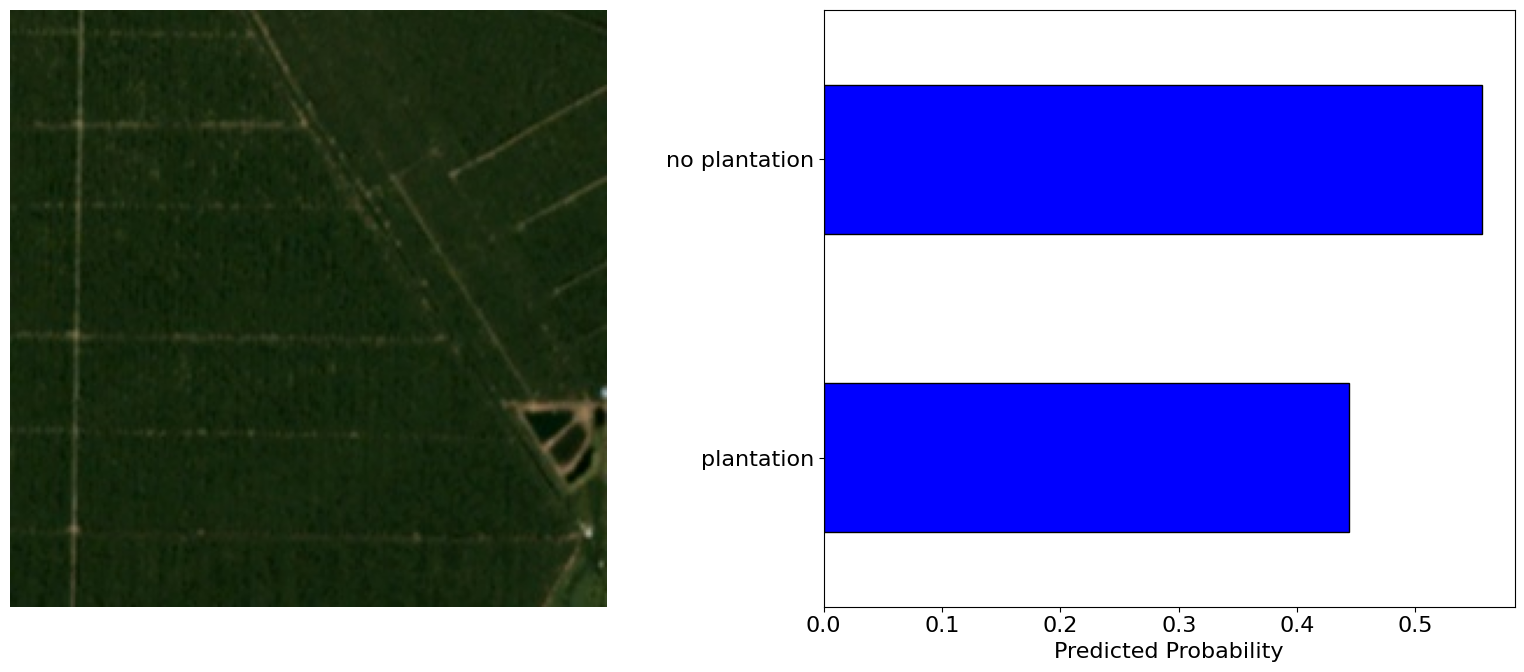

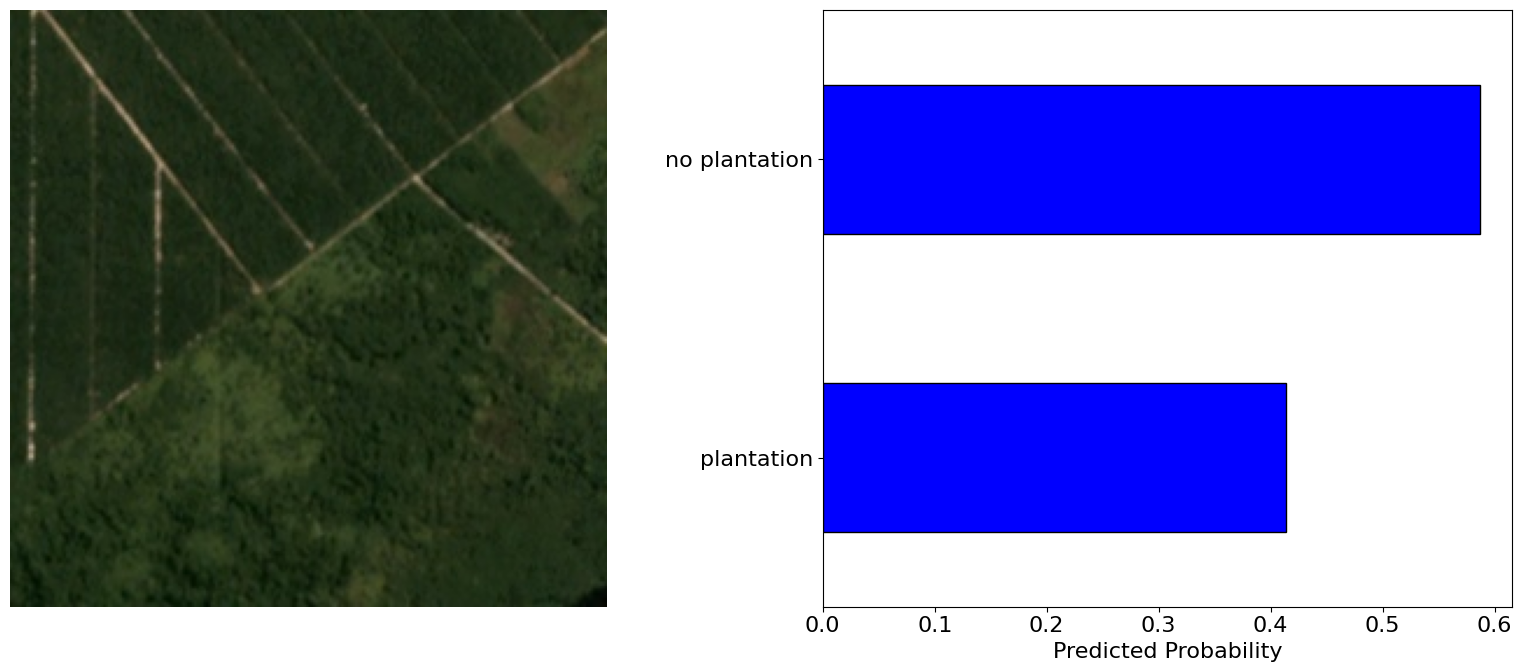

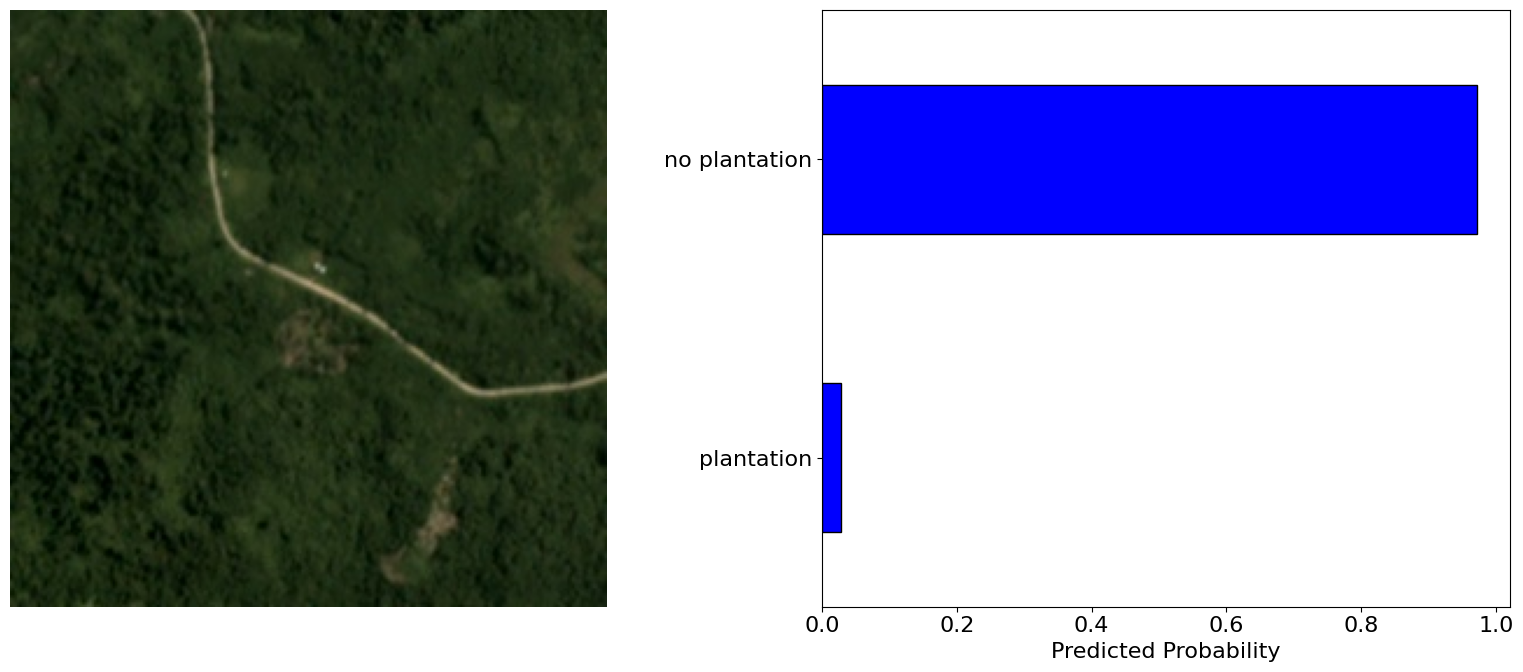

In [ ]:
labels = ["no plantation","plantation"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/widsdatathon2019/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/widsdatathon2019/leaderboard_holdout_data/img_01679.jpg')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/widsdatathon2019/leaderboard_holdout_data/img_07928.jpg')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/widsdatathon2019/leaderboard_holdout_data/img_06328.jpg')
fig = model.predict_image(image, labels, transform)